#**DATA UNDERSTANDING**



In [1]:
!pip install nltk

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
import string
from collections import Counter

from nltk.tokenize import word_tokenize,sent_tokenize,RegexpTokenizer
from nltk.corpus import stopwords,wordnet
from nltk.stem import PorterStemmer,WordNetLemmatizer,SnowballStemmer
from nltk.probability import FreqDist
from nltk import pos_tag
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.util import ngrams,bigrams
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('vader_lexicon')

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import(accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,ConfusionMatrixDisplay)


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


#**DATA LOADING**
The Skytrax Airline Review Dataset contains passenger feedback and other information about their flights.The file is stored in Excel format and will be uploaded into a Pandas DataFrame.

In [3]:
#load the dataset
df_airline = pd.read_excel("Skytrax Airline Review Data.xlsx")
df_airline

,review_date,over_all_rating,review_header,trip_verified,review_text,aircraft,type_of_traveller,seat_type,route,date_flown,seat_comfort,cabin_staff_service,food__beverages,inflight_entertainment,ground_service,wifi__connectivity,value_for_money,recommended,airline_name
0,2025-08-04,1.0,"""showed zero empathy for passengers""",Trip Verified,My afternoon flight was delayed and eventuall...,NaN,business,economy_class,dubai_to_kochi,august_2025,1.0,2.0,2.0,2.0,1.0,1.0,1.0,no,spicejet
1,2025-07-21,2.0,"""Extremely dissatisfied""",Trip Verified,The flight was postponed 3 times with insuffi...,NaN,family_leisure,economy_class,pune_to_dubai,july_2025,1.0,3.0,NaN,NaN,3.0,NaN,2.0,no,spicejet
2,2025-04-19,2.0,"""Very bad experience""",Trip Verified,They will charge you for your hand baggage if...,NaN,business,economy_class,mumbai_to_kolkata,april_2025,3.0,3.0,3.0,NaN,1.0,NaN,2.0,no,spicejet
3,2025-03-12,1.0,“What a difficult airline”,Trip Verified,The flight was delayed from 15:20 to 16:25. I...,NaN,business,economy_class,"pune,_india_to_new_delhi,_india",march_2025,3.0,4.0,NaN,NaN,5.0,NaN,1.0,no,spicejet
4,2025-03-02,2.0,“Poor chaotic boarding”,Trip Verified,No crowd control and boarding was like cattle...,boeing_747,solo_leisure,economy_class,mumbai_to_new_delhi,march_2025,3.0,1.0,3.0,NaN,1.0,NaN,2.0,no,spicejet
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64735,2015-07-23,7.0,Gulf Air customer review,NaN,The plane from London to Bahrain was awful - ...,NaN,family_leisure,economy_class,london_to_chennai_via_bahrain,may_2015,3.0,3.0,3.0,4.0,4.0,NaN,5.0,yes,gulf-air
64736,2015-06-19,6.0,Gulf Air customer review,NaN,London to Bahrain on board an A330. Check in ...,a330/320,couple_leisure,economy_class,lhr_to_abu_dhabi_via_bahrain,june_2015,2.0,2.0,3.0,3.0,3.0,NaN,4.0,no,gulf-air
64737,2015-06-15,8.0,Gulf Air customer review,NaN,I had read many reviews regarding their new F...,a330,business,business_class,bangkok_to_london_via_bahrain,may_2015,4.0,5.0,4.0,3.0,4.0,NaN,5.0,yes,gulf-air
64738,2015-05-08,9.0,Gulf Air customer review,NaN,I was up until 2 years ago a silver frequent ...,NaN,NaN,economy_class,NaN,NaN,4.0,5.0,4.0,5.0,NaN,NaN,4.0,yes,gulf-air


#**DATA INSPECTION**


Data Inspection helps us understand the structure and quality of the data before cleaning.

We will examine the number of records,the number of columns,the column names, their data types,the number of missing rows,number of duplicated entries and a statistical summary.



In [4]:
#inspecting the top 5 rows
df_airline.head(5)

,review_date,over_all_rating,review_header,trip_verified,review_text,aircraft,type_of_traveller,seat_type,route,date_flown,seat_comfort,cabin_staff_service,food__beverages,inflight_entertainment,ground_service,wifi__connectivity,value_for_money,recommended,airline_name
0,2025-08-04,1.0,"""showed zero empathy for passengers""",Trip Verified,My afternoon flight was delayed and eventuall...,NaN,business,economy_class,dubai_to_kochi,august_2025,1.0,2.0,2.0,2.0,1.0,1.0,1.0,no,spicejet
1,2025-07-21,2.0,"""Extremely dissatisfied""",Trip Verified,The flight was postponed 3 times with insuffi...,NaN,family_leisure,economy_class,pune_to_dubai,july_2025,1.0,3.0,NaN,NaN,3.0,NaN,2.0,no,spicejet
2,2025-04-19,2.0,"""Very bad experience""",Trip Verified,They will charge you for your hand baggage if...,NaN,business,economy_class,mumbai_to_kolkata,april_2025,3.0,3.0,3.0,NaN,1.0,NaN,2.0,no,spicejet
3,2025-03-12,1.0,“What a difficult airline”,Trip Verified,The flight was delayed from 15:20 to 16:25. I...,NaN,business,economy_class,"pune,_india_to_new_delhi,_india",march_2025,3.0,4.0,NaN,NaN,5.0,NaN,1.0,no,spicejet
4,2025-03-02,2.0,“Poor chaotic boarding”,Trip Verified,No crowd control and boarding was like cattle...,boeing_747,solo_leisure,economy_class,mumbai_to_new_delhi,march_2025,3.0,1.0,3.0,NaN,1.0,NaN,2.0,no,spicejet


In [5]:
#inspecting the bottom 5 columns
df_airline.tail(5)

,review_date,over_all_rating,review_header,trip_verified,review_text,aircraft,type_of_traveller,seat_type,route,date_flown,seat_comfort,cabin_staff_service,food__beverages,inflight_entertainment,ground_service,wifi__connectivity,value_for_money,recommended,airline_name
64735,2015-07-23,7.0,Gulf Air customer review,NaN,The plane from London to Bahrain was awful - ...,NaN,family_leisure,economy_class,london_to_chennai_via_bahrain,may_2015,3.0,3.0,3.0,4.0,4.0,NaN,5.0,yes,gulf-air
64736,2015-06-19,6.0,Gulf Air customer review,NaN,London to Bahrain on board an A330. Check in ...,a330/320,couple_leisure,economy_class,lhr_to_abu_dhabi_via_bahrain,june_2015,2.0,2.0,3.0,3.0,3.0,NaN,4.0,no,gulf-air
64737,2015-06-15,8.0,Gulf Air customer review,NaN,I had read many reviews regarding their new F...,a330,business,business_class,bangkok_to_london_via_bahrain,may_2015,4.0,5.0,4.0,3.0,4.0,NaN,5.0,yes,gulf-air
64738,2015-05-08,9.0,Gulf Air customer review,NaN,I was up until 2 years ago a silver frequent ...,NaN,NaN,economy_class,NaN,NaN,4.0,5.0,4.0,5.0,NaN,NaN,4.0,yes,gulf-air
64739,2015-05-05,9.0,Gulf Air customer review,NaN,On time departure both ways. A320 was in good...,NaN,NaN,economy_class,NaN,NaN,4.0,5.0,4.0,3.0,NaN,NaN,5.0,yes,gulf-air


In [6]:
#inspecting the shape of the dataset
df_airline.shape

(64740, 19)

In [7]:
#inspecting column names
df_airline.columns.tolist()

['review_date',
 'over_all_rating',
 'review_header',
 'trip_verified',
 'review_text',
 'aircraft',
 'type_of_traveller',
 'seat_type',
 'route',
 'date_flown',
 'seat_comfort',
 'cabin_staff_service',
 'food__beverages',
 'inflight_entertainment',
 'ground_service',
 'wifi__connectivity',
 'value_for_money',
 'recommended',
 'airline_name']

In [8]:
#inspecting the data types and non-null counts
df_airline.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64740 entries, 0 to 64739
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   review_date             64740 non-null  object 
 1   over_all_rating         64624 non-null  float64
 2   review_header           64740 non-null  object 
 3   trip_verified           53047 non-null  object 
 4   review_text             64593 non-null  object 
 5   aircraft                27973 non-null  object 
 6   type_of_traveller       62102 non-null  object 
 7   seat_type               64702 non-null  object 
 8   route                   61879 non-null  object 
 9   date_flown              62004 non-null  object 
 10  seat_comfort            61265 non-null  float64
 11  cabin_staff_service     61038 non-null  float64
 12  food__beverages         52149 non-null  float64
 13  inflight_entertainment  43578 non-null  float64
 14  ground_service          60053 non-null

In [9]:
#Generating descriptive statistics
df_airline.describe()

,over_all_rating,seat_comfort,cabin_staff_service,food__beverages,inflight_entertainment,ground_service,wifi__connectivity,value_for_money
count,64624.000000,61265.000000,61038.00000,52149.000000,43578.000000,60053.000000,23622.000000,64718.000000
mean,4.351000,2.840333,3.07243,2.803659,2.832966,2.584217,2.207772,2.609923
std,3.472791,1.461753,1.59222,1.513805,1.498890,1.618503,1.495944,1.602162
min,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000
50%,3.000000,3.000000,3.00000,3.000000,3.000000,2.000000,1.000000,2.000000
75%,8.000000,4.000000,5.00000,4.000000,4.000000,4.000000,3.000000,4.000000
max,10.000000,5.000000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000


In [10]:
#checking missing values
df_airline.isnull().sum()

,0
review_date,0
over_all_rating,116
review_header,0
trip_verified,11693
review_text,147
aircraft,36767
type_of_traveller,2638
seat_type,38
route,2861
date_flown,2736


In [11]:
#checking duplicated values
df_airline.duplicated().sum()

np.int64(64)

In [12]:
#count exact duplicate rows
print("Total duplicate rows:", df_airline.duplicated().sum())

# Preview every occurrence of duplicate rows
duplicates = df_airline[df_airline.duplicated(keep=False)]

print(duplicates.head(10))

Total duplicate rows: 64
      review_date  over_all_rating                            review_header  \
3749   2015-02-18              8.0      Philippine Airlines customer review   
3750   2015-02-18              8.0      Philippine Airlines customer review   
5639   2015-04-16              6.0                Air China customer review   
5640   2015-04-16              6.0                Air China customer review   
7825   2015-02-24              5.0          Jetstar Airways customer review   
7826   2015-02-24              5.0          Jetstar Airways customer review   
15918  2015-03-23             10.0  China Southern Airlines customer review   
15920  2015-03-23             10.0  China Southern Airlines customer review   
16732  2015-04-19              6.0             Thai Airways customer review   
16733  2015-04-19              6.0             Thai Airways customer review   

      trip_verified                                        review_text  \
3749            NaN   The price

In [13]:
unique_reviews = df_airline["review_text"].nunique()

print("Total records:",len(df_airline))
print("Unique review texts:",unique_reviews)
print("Repeated review text occurrences:",df_airline["review_text"].duplicated().sum())

Total records: 64740
Unique review texts: 64509
Repeated review text occurrences: 230


##**Data Inspection Findings**

The initial inspection of the airline passenger reviews dataset revealed that the dataset contains 64740 number of rows and 19 columns.Each row represents a passenger review,while the columns contain information about passenger experiences and airline services quality.

The column names and data types were examined to understand the structure of the dataset.The dataset contains numerical and categorical variables,including the overall rating,trip verification status,review text,aircraft,type of traveller,seat type,route and date flown.

The missing value analysis revealed that several columns contained missing values,with the wifi connectivity column having particularly high number of missing entries.Duplicate records were also examined to determine whether repeated entries could affect the analysis.

The statistical summary provided an overview of the numerical variables,including their central tendency and distribution.These findings  helped identify potential data quality issues that needed to be addressed during the data cleaning stage.

Overall, the inspection established the structure and quality of the dataset and identified missing values and possible duplicate records that required further investigation before exploratory data analysis and model development.

In [14]:
#Creating a backup of the original dataset
df_original = df_airline.copy()

# **DATA CLEANING**





###**1.MISSING VALUES**

Missing values occur when information is not recorded for a particular observation.

The initial inspection identified missing values in several columns.The reported counts include:
  
  -Overall rating:116 missing values.

  -Trip verified:11,693 missing values.

  -Review text: 147 missing values.

  -Aircraft:36767 missing values.

  -Type of traveler:2,638 missing values.

  -Seat type:38 missing values.

  -Route:2,861 missing values.

  -Date flown:2,736 missing values.

  -Seat comfort:3,475 missing values.

  -Cabin staff service:3,702 missing values.

  -Food beverages:12,591 missing values.

  -Inflight Entertainment: 21,162 missing values.

  -Ground service:4,687 missing values.

  -Wifi connectivity:41,118 missing values.

  -Value for money:22 missing values.

  -recommended:1 missing value.


  The treatment of missing values depends on the column.




In [15]:
#calculating the missing value count and percentage

missing_values = df_airline.isnull().sum()
missing_percentage = (df_airline.isnull().mean() * 100)

missing_summary = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage":missing_percentage
})
missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)
print(missing_summary.round(2))

                        Missing_Count  Missing_Percentage
wifi__connectivity              41118               63.51
aircraft                        36767               56.79
inflight_entertainment          21162               32.69
food__beverages                 12591               19.45
trip_verified                   11693               18.06
ground_service                   4687                7.24
cabin_staff_service              3702                5.72
seat_comfort                     3475                5.37
route                            2861                4.42
date_flown                       2736                4.23
type_of_traveller                2638                4.07
review_text                       147                0.23
over_all_rating                   116                0.18
seat_type                          38                0.06
value_for_money                    22                0.03
recommended                         1                0.00
review_date   

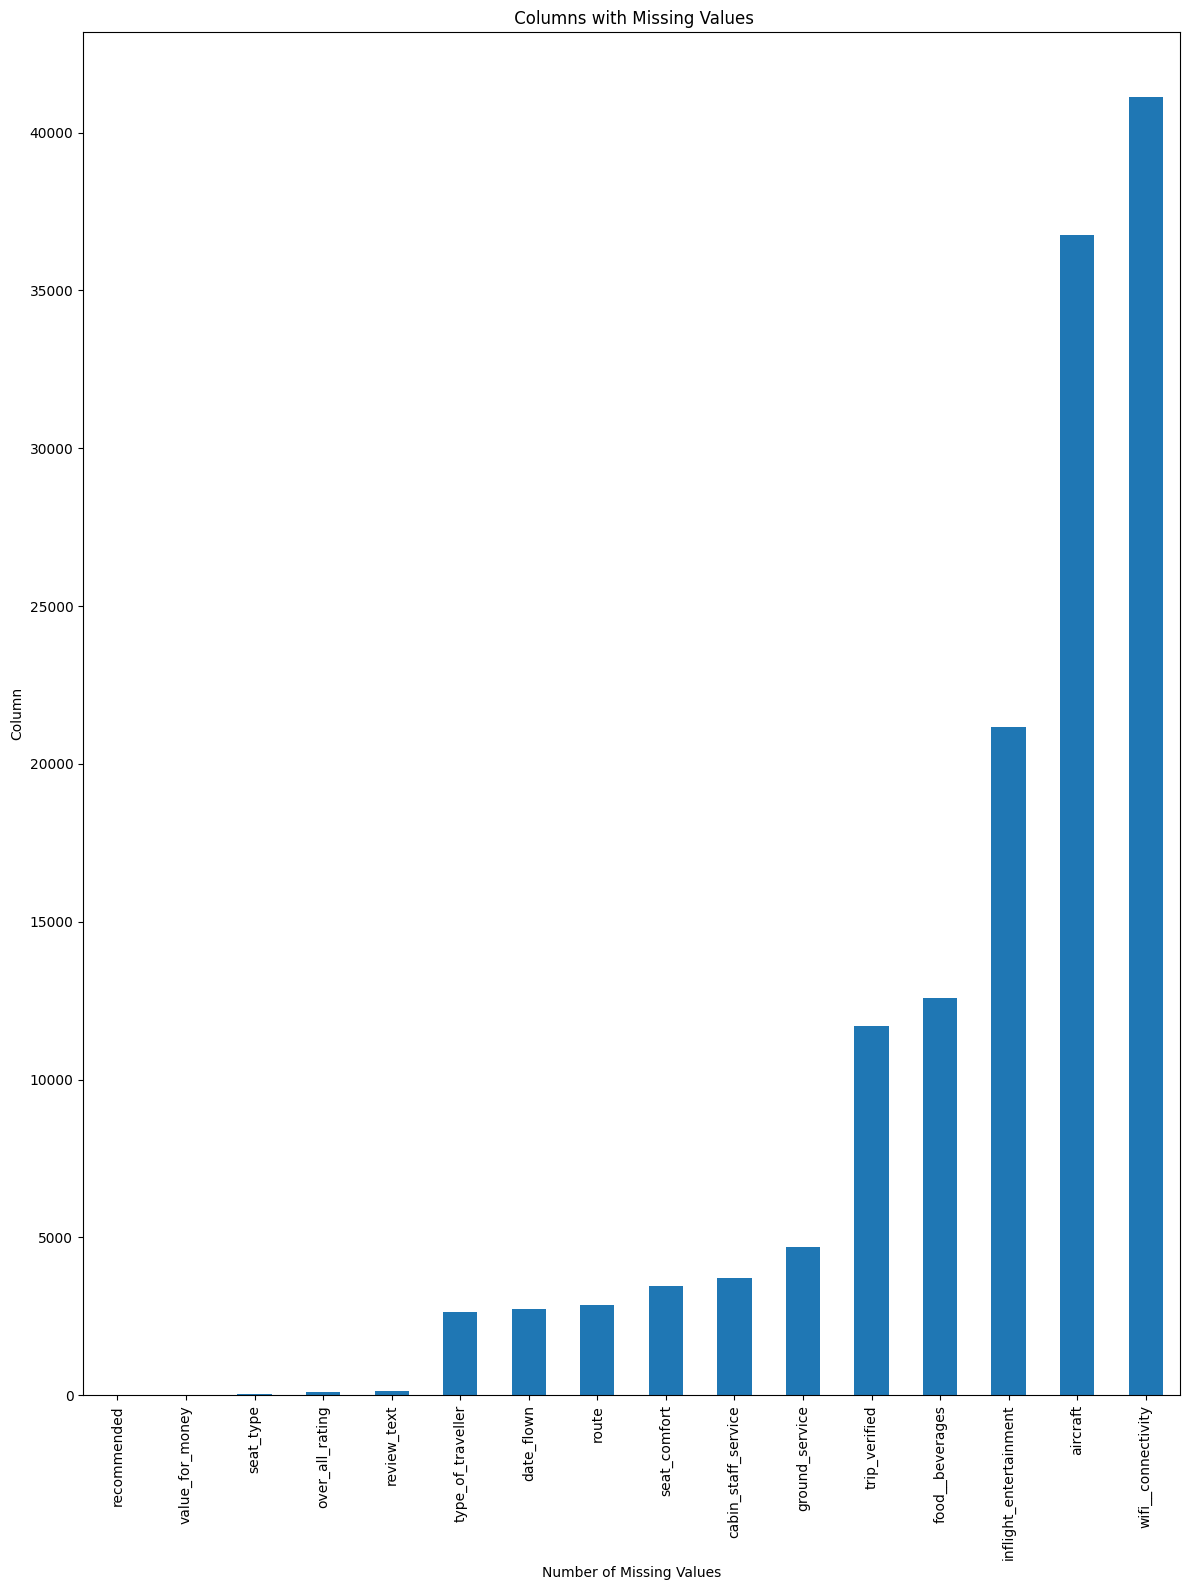

In [16]:
#visualize misssing values
missing_plot = missing_summary[
    missing_summary['Missing_Count'] > 0
].head(20)
plt.figure(figsize=(12,16))
missing_plot["Missing_Count"].sort_values().plot(kind="bar")
plt.title(" Columns with Missing Values")
plt.xlabel("Number of Missing Values")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

In [17]:
#Identify categorical and numerical columns
#display the data type of every column
print(df_airline.dtypes.to_frame(name="Data Type"))

#identify numerical columns
numerical_columns = df_airline.select_dtypes(include="number").columns.tolist()
#identify categorical and text columns
categorical_columns = df_airline.select_dtypes(include=['object','category','bool','string']).columns.tolist()

print("Numerical_columns:", numerical_columns)

print("Categorical Columns:", categorical_columns)

                       Data Type
review_date               object
over_all_rating          float64
review_header             object
trip_verified             object
review_text               object
aircraft                  object
type_of_traveller         object
seat_type                 object
route                     object
date_flown                object
seat_comfort             float64
cabin_staff_service      float64
food__beverages          float64
inflight_entertainment   float64
ground_service           float64
wifi__connectivity       float64
value_for_money          float64
recommended               object
airline_name              object
Numerical_columns: ['over_all_rating', 'seat_comfort', 'cabin_staff_service', 'food__beverages', 'inflight_entertainment', 'ground_service', 'wifi__connectivity', 'value_for_money']
Categorical Columns: ['review_date', 'review_header', 'trip_verified', 'review_text', 'aircraft', 'type_of_traveller', 'seat_type', 'route', 'date_flown', 're

In [18]:
#excluded the recommended and review text columns
excluded_columns = ['review_text','recommended']
#numerical columns to impute
numerical_columns_fill = [
    col for col in numerical_columns
    if col not in excluded_columns
]
#categorical columns to impute
categorical_columns_fill = [
col for col in categorical_columns
if col not in excluded_columns
]


print("Numerical columns to fill:")
print(numerical_columns_fill)

print("\nCategorical columns to fill:")
print(categorical_columns_fill)

Numerical columns to fill:
['over_all_rating', 'seat_comfort', 'cabin_staff_service', 'food__beverages', 'inflight_entertainment', 'ground_service', 'wifi__connectivity', 'value_for_money']

Categorical columns to fill:
['review_date', 'review_header', 'trip_verified', 'aircraft', 'type_of_traveller', 'seat_type', 'route', 'date_flown', 'airline_name']


In [19]:
#handling missing values in numerical columns

#converting the ratings to numeric values
for col in numerical_columns_fill:
  df_airline[col] = pd.to_numeric(df_airline[col],errors='coerce')

df_airline[numerical_columns_fill] = df_airline[numerical_columns_fill].fillna(df_airline[numerical_columns_fill].median())

In [20]:
#confirming
df_airline.isnull().sum()

,0
review_date,0
over_all_rating,0
review_header,0
trip_verified,11693
review_text,147
aircraft,36767
type_of_traveller,2638
seat_type,38
route,2861
date_flown,2736


In [21]:
#handling missing values in categorical columns
df_airline[categorical_columns_fill] = df_airline[categorical_columns_fill].fillna('Unknown')

In [22]:
#confirmation
df_airline.isnull().sum()

,0
review_date,0
over_all_rating,0
review_header,0
trip_verified,0
review_text,147
aircraft,0
type_of_traveller,0
seat_type,0
route,0
date_flown,0


In [23]:
#Handle missing values in recommended and review text column
df_airline = df_airline.dropna(subset=["review_text","recommended"])

In [24]:
#confirmation
df_airline.isnull().sum()

,0
review_date,0
over_all_rating,0
review_header,0
trip_verified,0
review_text,0
aircraft,0
type_of_traveller,0
seat_type,0
route,0
date_flown,0


In [25]:
df_airline.shape

(64592, 19)

###**HANDLING DUPLICATES**

Duplicate records are repeated observations in a dataset.They can affect analysis by giving repeated information more weight than intended.

We will first count the exact duplicate rows.We will then remove exact duplicates while keeping the first occurrence.

In [26]:
 # Drop the extra copies and remain with one copy.
df_airline = df_airline.drop_duplicates().copy()

print("Dataset shape after removing exact duplicates:", df_airline.shape)

Dataset shape after removing exact duplicates: (64528, 19)


In [27]:
# Count repeated non-missing review texts
print(
    "Repeated review texts:",
    df_airline["review_text"].dropna().duplicated().sum()
)

Repeated review texts: 20


In [29]:
duplicate_reviews = df_airline[
    df_airline["review_text"].notna()
    & df_airline["review_text"].duplicated(keep=False)
]

duplicate_reviews[
    ["airline_name","review_date","review_header",
     "review_text", "recommended"]
].sort_values("review_text").head(20)

,airline_name,review_date,review_header,review_text,recommended
5029,airasia-x,2015-11-13,"""I got what I paid for""",The booking experience was fine. Had already...,yes
11573,airasia,2015-11-13,"""I got what I paid for""",The booking experience was fine. Had already...,yes
41389,american-airlines,2024-07-10,"""ruined the first day of a vacation""",American completely ruined the first day of a...,no
41388,american-airlines,2024-07-10,"""ruined the first day of a vacation""",American completely ruined the first day of a...,no
5925,srilankan-airlines,2018-07-21,"""good staff service""",Both flights was on the A321 and the flight f...,yes
5926,srilankan-airlines,2018-07-20,"""great food and good staff service""",Both flights was on the A321 and the flight f...,yes
10895,vistara,2016-02-10,"""Great experience""",Check in was very smooth with many open count...,yes
10894,vistara,2016-02-10,"""welcome new full service""",Check in was very smooth with many open count...,yes
51331,jetblue-airways,2021-06-14,"""let you know about delay less than an hour be...",Do I need to wait in a crowded airport with h...,no
51334,jetblue-airways,2021-06-11,"""let you know about a 5 hour delay""",Do I need to wait in a crowded airport with h...,no


In [30]:
df_airline = df_airline.drop_duplicates(subset=["review_text"], keep="first").copy()

In [33]:
#confirming
df_airline["review_text"].duplicated().sum()

np.int64(0)

In [34]:
df_airline.shape

(64508, 19)

##**DATA CLEANING SUMMARY AND JUSTIFICATION**

Data Cleaning was performed to improve the quality and realibilty of the airline passenger reviews dataset before exploratory data analysis, text preprocessing and model development.The process focused on handling missing values and duplicate records while preserving useful information for the project.

***1.Handling Missing Values***

The dataset contained missing values in both numerical anad categorical columns.Different methods were selected depending on the data type and the purpose of each variable.

a.)**Numerical Columns**:Missing values in numerical columns were handled using median imputation.The median was chosen because it is less sensitive to extreme values and outliers than mean,making it a suitable option for numerical variables such as service ratings.

b.)**Categorical Columns**:Missing values in the remaining categorical columns were replaced with "**Unknown**".This approach preserves records while explicitly indicating that information was unavailable,rather than assigning an unsupported category to the passsenger.

c.)**Review text column**: Missing and empty review texts were removed because the project uses passenger reviews as input features for BERT and DistilBERT.Filling missing reviews with 'Unkown" would introduce text that does not represent an actual passenger experience and could negatively affect model learning.

d.)**Recommended column**:Rows with missing recommendation labels were removed  because the recommendation column is the target variable for the binary classification task.Imputing these values could introduce incorrect labels and mislead the models during training.

The review text and recommendation columns were therefore excluded from general numerical and categorical imputation and handled separately.


***2.Handling Duplicate Records***

**a.)Exact duplicate rows**

During data cleaning,64 exact duplicate rows were identified in the airline passenger reviews dataset.These rows were removed using drop_duplicates(keep="first") to retain one occurrence of each unique row.

**b.)Repeated review texts**

After removing exact duplicate rows,20 additional rows containing repeated review texts were identified and removed.The review_text column was used to identify these records, and drop_duplicates(subset=["review_text"],keep="first") was applied to retain one occurence of each review text.



***3.Verification After Cleaning***

After Handling missing values and duplicates,the dataset was checked again to assess the results of the cleaning operations.The remaining missing values,empty reviews,duplicate records,and the dataset dimensions were examined to verify the quality of the resulting data.

**CONCLUSION**

The dataset initially contained 64,740 rows. after removing 64 exact duplicate rows,20 additional rows with repeated review texts, and 148 rows with missing review text values,the final dataset contained 64,508 rows.


#**NLP**

###**TEXT PREPROCESSING**



In [35]:
#creating the preprocessing tools
stop_words = set(stopwords.words('english'))
porter_stemmer = PorterStemmer()
snowball_stemmer = SnowballStemmer('english')
lemmatizer = WordNetLemmatizer()

# creaing the preprocess_text function

def preprocess_text(text):
  if not isinstance(text,str):
    return[]
  #convert to lowercase
  text = text.lower()
  #removes url
  text = re.sub(r'http\s+|www\s+','',text)
  #tokenization
  sentence = sent_tokenize(text)
  tokens =word_tokenize(text)
  #keep alphabets only
  tokens = [word for word in tokens if word.isalpha()]
  #remove stopwords
  tokens = [word for word in tokens if word not in stop_words]
  #lemmatize the tokens
  tokens = [lemmatizer.lemmatize(word) for word in tokens]
  return tokens

In [36]:
df_airline['processed_tokens'] = df_airline['review_text'].apply(preprocess_text)
df_airline['processed_tokens']

,processed_tokens
0,"[afternoon, flight, delayed, eventually, flew,..."
1,"[flight, postponed, time, insufficient, explan..."
2,"[charge, hand, baggage, exceeds, including, la..."
3,"[flight, delayed, passed, air, india, ticket, ..."
4,"[crowd, control, boarding, like, cattle, herde..."
...,...
64735,"[plane, london, bahrain, awful, delayed, board..."
64736,"[london, bahrain, board, check, fast, issue, b..."
64737,"[read, many, review, regarding, new, falcon, g..."
64738,"[year, ago, silver, frequent, flyer, visited, ..."


In [37]:
# Calculate word count
df_airline["word_count"] = (
    df_airline["processed_tokens"].apply(
        lambda tokens: len(tokens) if isinstance(tokens, list) else 0
    )
)

print(df_airline["word_count"].head())

0    73
1    51
2    15
3    44
4    50
Name: word_count, dtype: int64


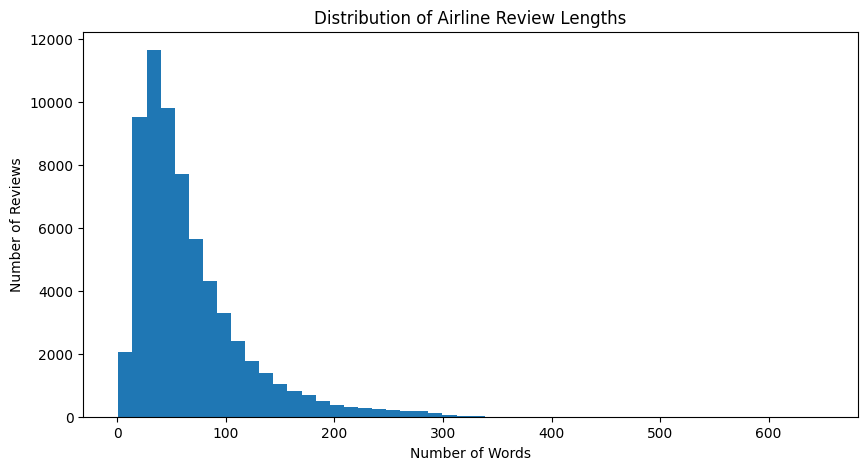

In [ ]:
#visualize review lengths
plt.figure(figsize=(10,5))
plt.hist(df_airline["word_count"],bins=50)
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.title("Distribution of Airline Review Lengths")
plt.show()

In [38]:
# Inspect short reviews
print(
    df_airline.loc[
        df_airline["word_count"] <= 3,
        ["review_text", "processed_tokens", "recommended"]
    ].head(10)
)

                                         review_text  \
810                        What a bunch of scammers!   
1704         No spare aircraft was there on standby.   
1765                 1 hour delayed. Not dependable.   
3062                           There were no delays.   
7052                          Shame on you, Jetstar.   
7077                         $120. Cab fee and $450.   
7845   5/5 for such hospitality and customer delight   
7972                      Thank you Brunei Airlines.   
8131                                   Great flight.   
8234           No other help or compensation offered   

                      processed_tokens recommended  
810                   [bunch, scammer]          no  
1704        [spare, aircraft, standby]         yes  
1765       [hour, delayed, dependable]          no  
3062                           [delay]         yes  
7052                  [shame, jetstar]          no  
7077                        [cab, fee]         yes  
7845  [hospi

In [39]:
#defining X and Y
#independent variable(input feature)
X = df_airline["processed_tokens"]
#dependent variable
y = df_airline["recommended"]


In [40]:
#Encode the target variable
target_mapping = {
    "yes":1,
    "no":0
}
y = y.map(target_mapping)
print(y.value_counts(dropna=False))

recommended
0    39813
1    24695
Name: count, dtype: int64


**Natural Language Processing (NLP) and Text Preprocessing***

Natural Language Processing (NLP) was used to prepare airline passenger reviews for machine learning. The review_text column contains unstructured textual data, so preprocessing and text representation are necessary to make reviews suitable for classification. Word count analysis was perfomed to examine review lengths,and a bar chart was used to visualize the differences. Short reviews were also inspected to identify reviews containing very few words that might provide limited information for predicting passenger recommendations,

The recommended column was encoded into binary classes,where 0 represents passengers who do not recommend the airline and 1 represents passengers who recommmend it. The dataset contained 39,813 class 0 observations and 24,695 class 1 observations,indicating that non-recommended reviews were more common.

The input variable X, was defined as the review_text column because it contains the textual information used for prediction,while the target variable,y, was defined as the recommended column because it contains the outcome the models were trained to predict.

In [41]:
#splitting the dataset
X_train,X_test,y_train,y_test = train_test_split(
      X,
      y,
      test_size=0.20,
      random_state=42,
      stratify=y
)
print("Training set size:",X_train.shape[0])
print("Testing set size:",X_test.shape[0])

print("\nTraining target distribuion:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training set size: 51606
Testing set size: 12902

Training target distribuion:
recommended
0    0.617176
1    0.382824
Name: proportion, dtype: float64

Testing target distribution:
recommended
0    0.617191
1    0.382809
Name: proportion, dtype: float64


In [42]:
#converting text to numbers
tfidf = TfidfVectorizer(
    lowercase=False,
    ngram_range=(1,2),
    min_df=2,
    max_df=0.95,
    max_features=20000,
    sublinear_tf=True
)

In [43]:
# Convert token lists into strings
X_train = X_train.apply(
    lambda tokens: " ".join(tokens)
    if isinstance(tokens, list)
    else str(tokens)
)

X_test = X_test.apply(
    lambda tokens: " ".join(tokens)
    if isinstance(tokens, list)
    else str(tokens)
)

In [44]:
#Model 1 Multinomial Naive Bayes
nb_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=False,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        max_features=20000,
        sublinear_tf=True
    )),
    ("classifier", MultinomialNB())
])

nb_model.fit(X_train, y_train)

print("Multinomial Naive Bayes training complete.")

Multinomial Naive Bayes training complete.


In [56]:
#make predictions for Multinomial Naive Bayes model
y_pred_nb = nb_model.predict(X_test)
print("First 10 actual labels:")
print(y_test.iloc[:10].values)
print("\nFirst 10 predicted labels:")
print(y_pred_nb[:10])

First 10 actual labels:
[0 1 1 1 0 0 1 0 0 1]

First 10 predicted labels:
[0 1 0 1 0 1 1 0 1 1]


In [46]:
#model 2: SVM model
svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=False,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        max_features=20000,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        random_state=42,
        max_iter=2000
    ))
])

svm_model.fit(X_train, y_train)

print("Linear SVM training complete.")

Linear SVM training complete.


In [47]:
#predictions for svm model
y_pred_svm = svm_model.predict(X_test)

print("First 10 actual labels:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted labels:")
print(y_pred_svm[:10])

First 10 actual labels:
[0 1 1 1 0 0 1 0 0 1]

First 10 predicted labels:
[0 1 0 1 0 1 1 0 0 1]


In [48]:
#model 3 Logistic Regression
lr_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=False,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        max_features=20000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight=None,
        random_state=42
    ))
])

lr_model.fit(X_train, y_train)

print("Logistic Regression training complete.")

Logistic Regression training complete.


In [49]:
y_pred_lr = lr_model.predict(X_test)

print("First 10 actual labels:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted labels:")
print(y_pred_lr[:10])

First 10 actual labels:
[0 1 1 1 0 0 1 0 0 1]

First 10 predicted labels:
[0 1 1 1 0 0 1 0 0 1]


**Modelling:Vectorization,Training and Predictions***

The dataset was divided into training and testing sets using 80:20 split,producing 51,606 training observations and 12,902 testing observations. The similar target distributions in both sets,with approximately 61.72% class 0 and 38.28% class 1, indicate that the original class proportions were maintained.The training set was used to learn patterns from the review_text,while the testing set was reserved for evaluating predictions on unseen data.

TF-IDF Vectorization was used to represent the review_text numerically by assigning importance to words based on their frequency within reviews and across the dataset. This representation was suitable for traditional text classification algorithms.Three models were selected for comparion. Multinomial Naive Bayes was chosen as a computationally efficient baseline commonly used for text classification.Logistic Regression was selected because it is effective for binary calssification and can  perform well with high-dimensional text features.Linear Support Vector Machine(SVM) was selected because it is well suited to high-dimensional textual data learns a decision boundary between the two classes.

Each model was trained using the vectorized training reviews and then used to predict the recommended labels in the testing set. Comparing their predictions allows us to determine which algorithm best identifies passengers who recommend or do not recommend an airline.This comparison also establishes a baseline for evaluating BERT and DistilBERT in the next stage of the project.

In [50]:
#evaluation function
def evaluate_model(model_name, y_true, y_pred):

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, y_pred, pos_label=1, zero_division=0
        )
    }


In [51]:
#compare all three models
results = []

results.append(
    evaluate_model("Multinomial Naive Bayes", y_test, y_pred_nb)
)

results.append(
    evaluate_model("Logistic Regression", y_test, y_pred_lr)
)

results.append(
    evaluate_model("Linear SVM", y_test, y_pred_svm)
)

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1-Score",
        ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.923965,0.919635,0.878113,0.898395
1,Linear SVM,0.919625,0.906458,0.880948,0.893521
2,Multinomial Naive Bayes,0.879244,0.820474,0.876291,0.847464


In [52]:
#detailed classification report
print("MULTINOMIAL NAIVE BAYES")
print(classification_report(y_test, y_pred_nb, zero_division=0))

print("\nLOGISTIC REGRESSION")
print(classification_report(y_test, y_pred_lr, zero_division=0))

print("\nLINEAR SVM")
print(classification_report(y_test, y_pred_svm, zero_division=0))

MULTINOMIAL NAIVE BAYES
              precision    recall  f1-score   support

           0       0.92      0.88      0.90      7963
           1       0.82      0.88      0.85      4939

    accuracy                           0.88     12902
   macro avg       0.87      0.88      0.87     12902
weighted avg       0.88      0.88      0.88     12902


LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.93      0.95      0.94      7963
           1       0.92      0.88      0.90      4939

    accuracy                           0.92     12902
   macro avg       0.92      0.92      0.92     12902
weighted avg       0.92      0.92      0.92     12902


LINEAR SVM
              precision    recall  f1-score   support

           0       0.93      0.94      0.94      7963
           1       0.91      0.88      0.89      4939

    accuracy                           0.92     12902
   macro avg       0.92      0.91      0.91     12902
weighted avg     

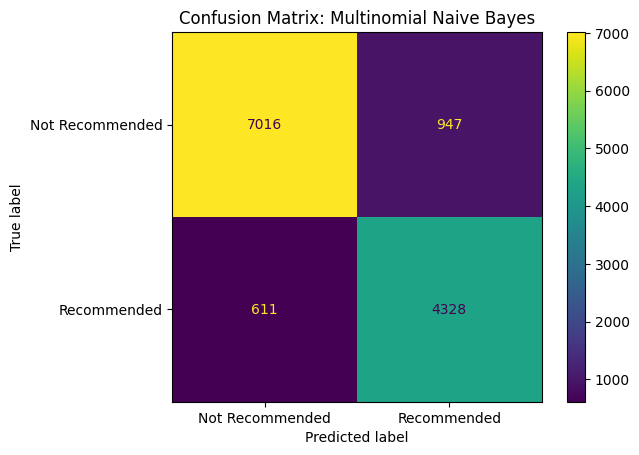

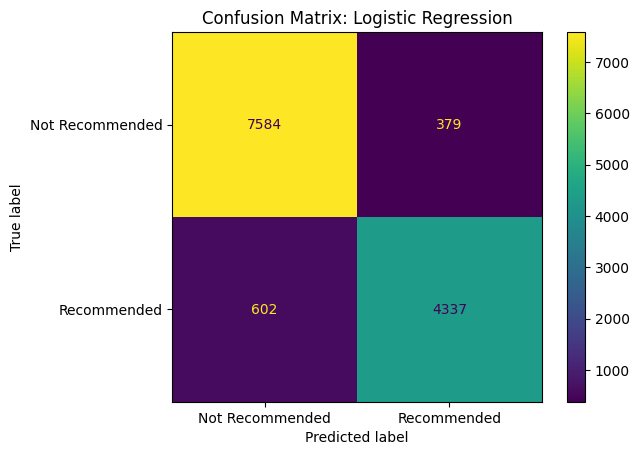

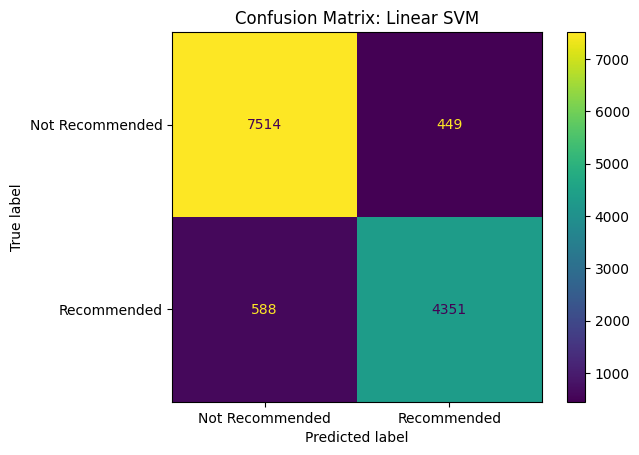

In [53]:
#confusion matrices
predictions = {
    "Multinomial Naive Bayes": y_pred_nb,
    "Logistic Regression": y_pred_lr,
    "Linear SVM": y_pred_svm
}

for model_name, predictions_model in predictions.items():

    cm = confusion_matrix(
        y_test,
        predictions_model,
        labels=[0, 1]
    )

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Recommended", "Recommended"]
    )

    display_cm.plot()

    plt.title(f"Confusion Matrix: {model_name}")
    plt.show()

In [54]:
best_model_row = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print("Best model based on F1-score:")
print(best_model_row)

Best model based on F1-score:
Model        Logistic Regression
Accuracy                0.923965
Precision               0.919635
Recall                  0.878113
F1-Score                0.898395
Name: 1, dtype: object


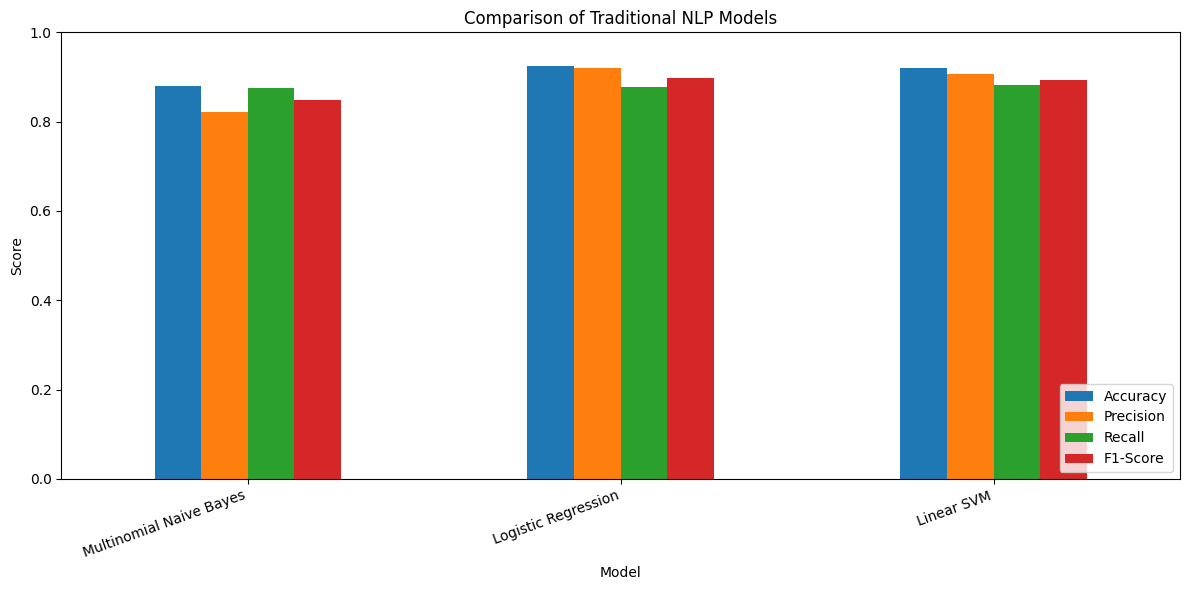

In [55]:
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Traditional NLP Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Model Evaluation and Findings***

The three models were evaluated using accuracy,precision,recall,F1-Score and support. These metrics were used because accuracy alone may not fully describe model performance when the target classes have different proportions.Precision measures the reliability of positive predictions,recall measures how many actual cases are correctly identifid,and the F1-score balances precision and recall.


Multinomial Naive Bayes achieved 88% accuracy,with an F1-score of 85% for class 1 and 90% for class 0.Logistic Regression achieved 92% accuracy, with F1-scores of 90%  for class 1 and 94% for class 0.Linear SVM also achieved 93% accuracy with F1_scores of 89% for class 1 and 94% for class 0.These results show that Lofistic Regression and Linear SVM performed better overall than Multinomial Naive Bayes.


Logistic Regression was selected as the best-performing traditional model because it achieved the highest micro_average F1-score of 92% and the highest class 1 precision and F1-SCORE,at 92% and 90% respectively.Although Linear SVM achieved the same accuracy,Logistic Regression performed slightly better at identifying recommended reviews.This makes it the strongest candidate among the three models based on the reported evaluation metrics.Its perfomance will serve as a benchmark for comparing BERT and DistilBERT to determine whether transformer-based models can improve the prediction of airline passenger recommendations